In [4]:
!pip -q install opencv-python
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
from pathlib import Path

print("OpenCV version:", cv2.__version__)


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


OpenCV version: 4.10.0


In [5]:
def show_bgr(img_bgr, title="", figsize=(6,6)):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(img_rgb)
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_gray(img_gray, title="", figsize=(6,6)):
    plt.figure(figsize=figsize)
    plt.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")
    plt.show()

def show_many(images, titles, cmap=None, figsize=(16,8), ncols=3):
    n = len(images)
    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=figsize)
    for i, img in enumerate(images):
        plt.subplot(nrows, ncols, i + 1)
        if len(img.shape) == 2:
            plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(titles[i])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Đường dẫn ảnh: ../img/bien-so-xe-theo-phong-thuy.jpg
Kích thước ảnh: (520, 780, 3)


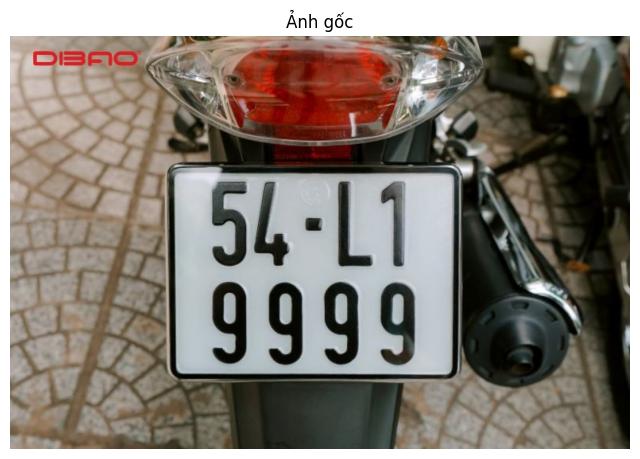

In [6]:
try:
    from google.colab import files
    uploaded = files.upload()
    image_path = next(iter(uploaded.keys()))
except Exception:
    image_path = "../img/bien-so-xe-theo-phong-thuy.jpg"

print("Đường dẫn ảnh:", image_path)

img = cv2.imread(image_path)
if img is None:
    raise ValueError("Không đọc được ảnh. Hãy kiểm tra lại tên file hoặc upload lại ảnh.")

print("Kích thước ảnh:", img.shape)
show_bgr(img, "Ảnh gốc", figsize=(8,6))

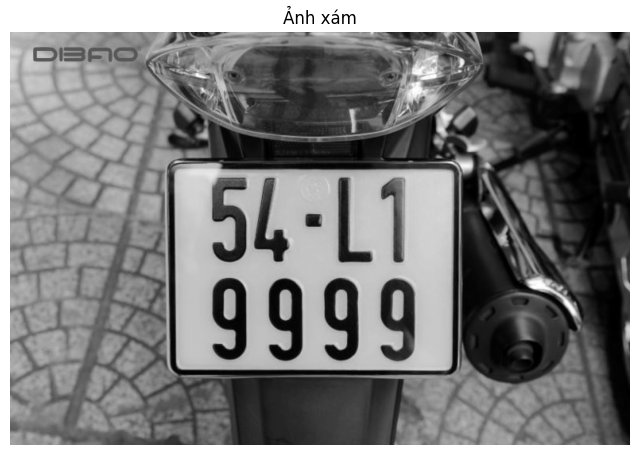

In [7]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show_gray(gray, "Ảnh xám", figsize=(8,6))


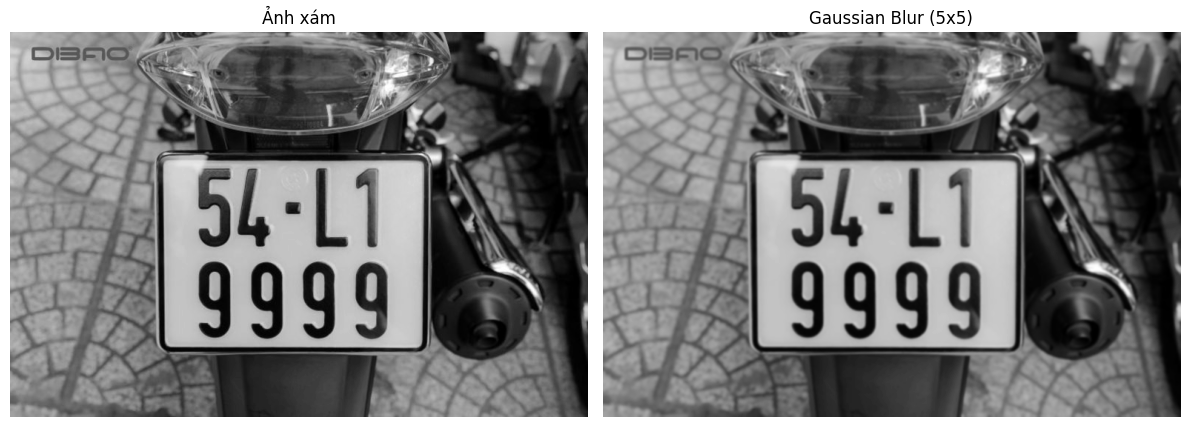

In [8]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)

show_many(
    [gray, blur],
    ["Ảnh xám", "Gaussian Blur (5x5)"],
    figsize=(12,5),
    ncols=2
)

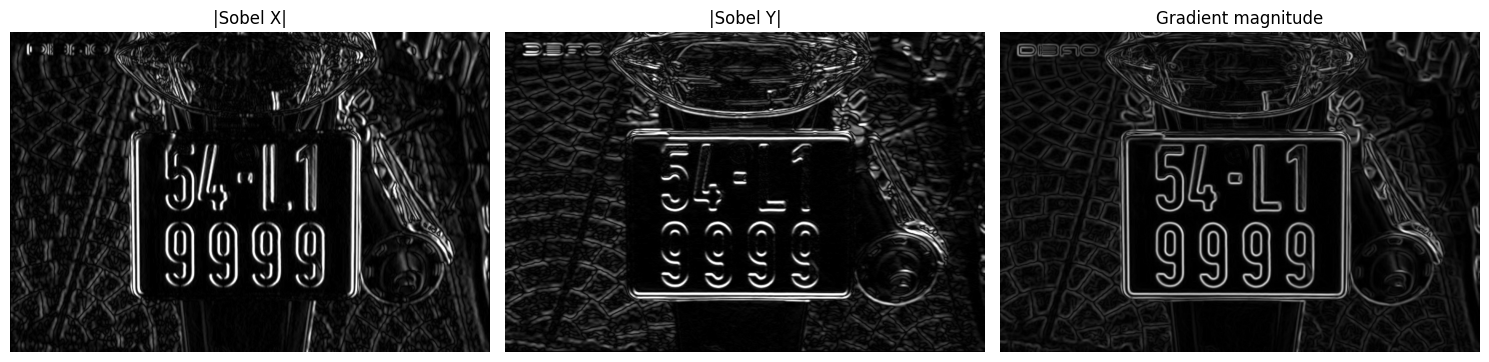

In [9]:
sobel_x = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)

sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

grad_mag = cv2.magnitude(sobel_x, sobel_y)
grad_mag_u8 = cv2.normalize(grad_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

show_many(
    [sobel_x_abs, sobel_y_abs, grad_mag_u8],
    ["|Sobel X|", "|Sobel Y|", "Gradient magnitude"],
    figsize=(15,5),
    ncols=3
)

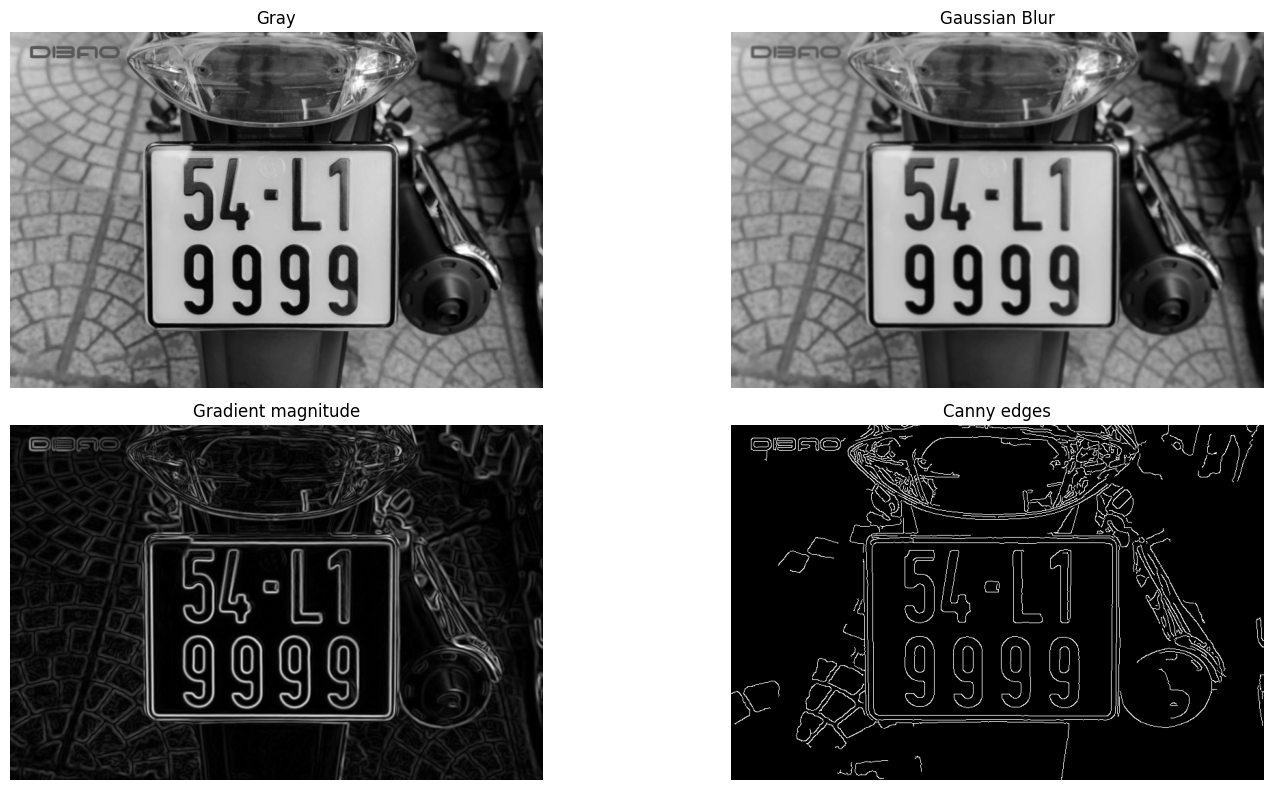

In [10]:
edges = cv2.Canny(blur, 50, 150)

show_many(
    [gray, blur, grad_mag_u8, edges],
    ["Gray", "Gaussian Blur", "Gradient magnitude", "Canny edges"],
    figsize=(16,8),
    ncols=2
)

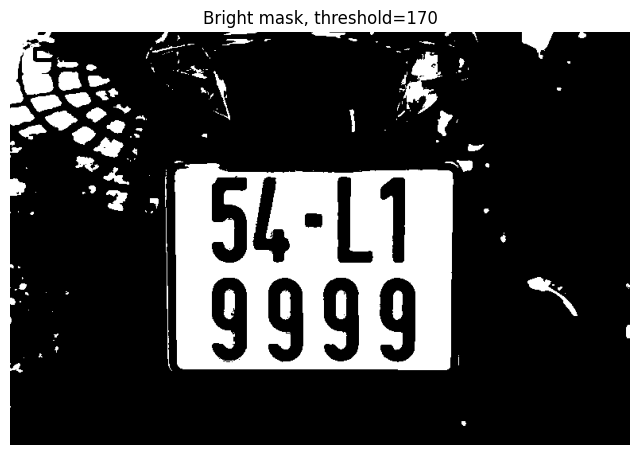

In [11]:
threshold_value = 170
_, bright_mask = cv2.threshold(gray, threshold_value, 255, cv2.THRESH_BINARY)

show_gray(bright_mask, f"Bright mask, threshold={threshold_value}", figsize=(8,6))

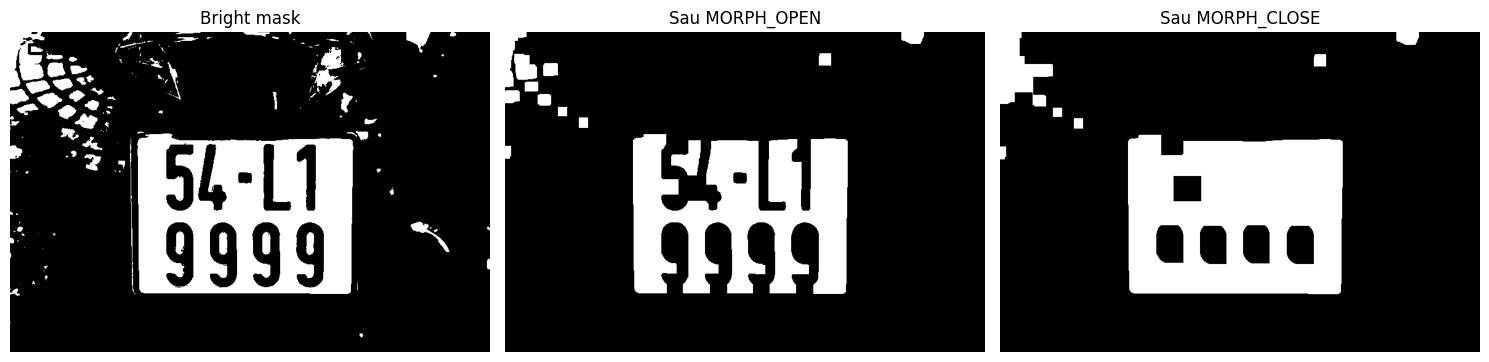

In [12]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
mask_open = cv2.morphologyEx(bright_mask, cv2.MORPH_OPEN, kernel)
mask_clean = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, kernel, iterations=2)

show_many(
    [bright_mask, mask_open, mask_clean],
    ["Bright mask", "Sau MORPH_OPEN", "Sau MORPH_CLOSE"],
    figsize=(15,5),
    ncols=3
)

Số ứng viên: 1
Danh sách ứng viên: [(85262.5, 208, 167, 349, 259, 0.9432631567197701)]


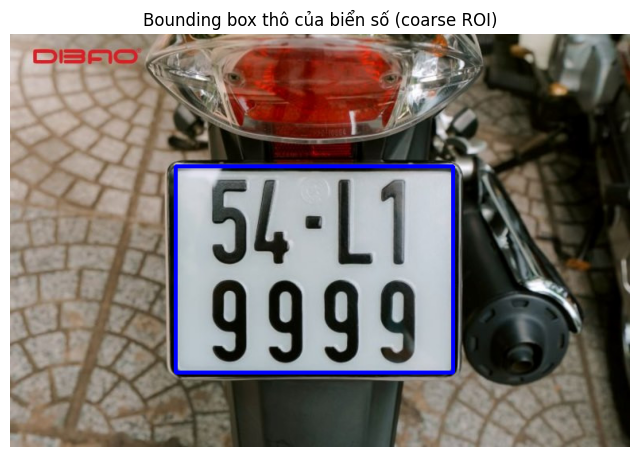

Coarse ROI: x=208, y=167, w=349, h=259


In [13]:
contours, _ = cv2.findContours(mask_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

candidates = []
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    area = cv2.contourArea(c)
    ar = w / h
    fill_ratio = area / (w * h + 1e-6)
    if area > 50000 and 1.2 < ar < 2.2 and fill_ratio > 0.5:
        candidates.append((area, x, y, w, h, fill_ratio))

print("Số ứng viên:", len(candidates))
print("Danh sách ứng viên:", candidates)

if len(candidates) == 0:
    raise ValueError("Không tìm được ROI ứng viên. Hãy thử lại threshold hoặc kernel morphology.")

candidates = sorted(candidates, reverse=True)
_, x0, y0, w0, h0, fill0 = candidates[0]

coarse_vis = img.copy()
cv2.rectangle(coarse_vis, (x0, y0), (x0 + w0, y0 + h0), (255, 0, 0), 4)

show_bgr(coarse_vis, "Bounding box thô của biển số (coarse ROI)", figsize=(8,6))
print(f"Coarse ROI: x={x0}, y={y0}, w={w0}, h={h0}")

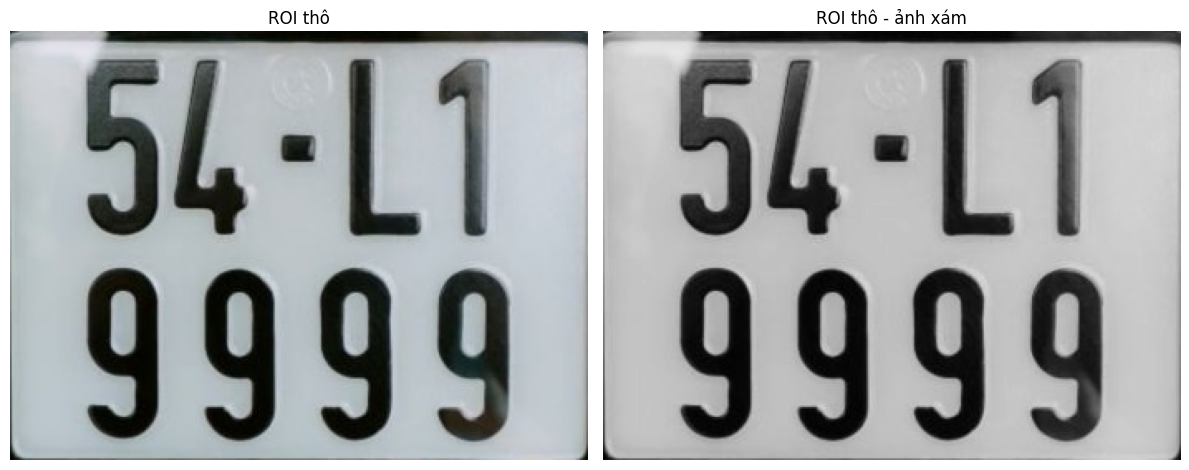

In [14]:
roi = img[y0:y0+h0, x0:x0+w0]
roi_gray = gray[y0:y0+h0, x0:x0+w0]

show_many(
    [roi, roi_gray],
    ["ROI thô", "ROI thô - ảnh xám"],
    figsize=(12,5),
    ncols=2
)

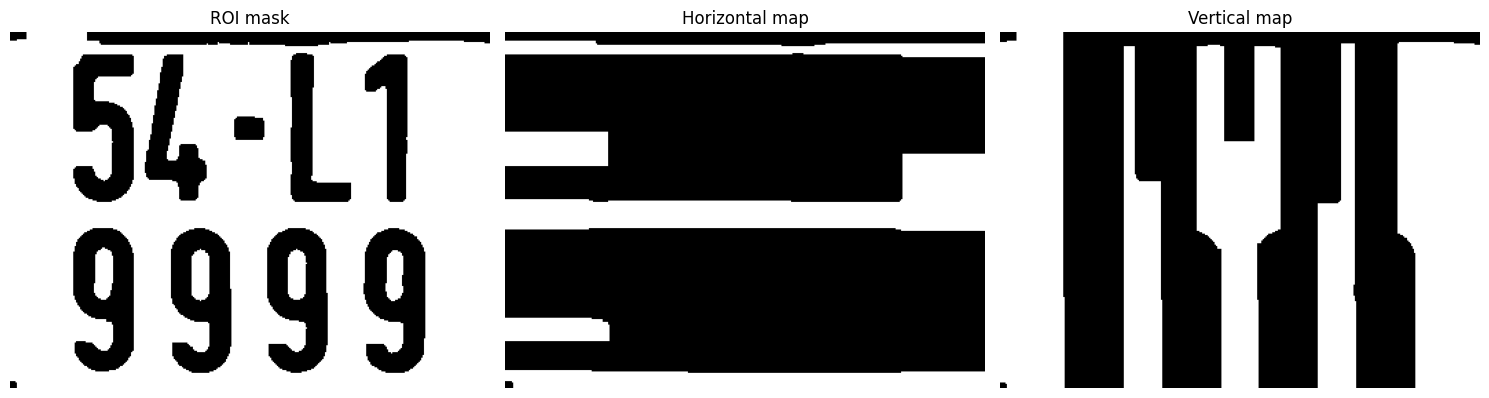

In [15]:
_, roi_mask = cv2.threshold(roi_gray, threshold_value, 255, cv2.THRESH_BINARY)
roi_mask = cv2.morphologyEx(
    roi_mask,
    cv2.MORPH_CLOSE,
    cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)),
    iterations=1
)

h_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (120, 5))
v_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 120))

horizontal_map = cv2.morphologyEx(roi_mask, cv2.MORPH_OPEN, h_kernel)
vertical_map   = cv2.morphologyEx(roi_mask, cv2.MORPH_OPEN, v_kernel)

show_many(
    [roi_mask, horizontal_map, vertical_map],
    ["ROI mask", "Horizontal map", "Vertical map"],
    figsize=(15,5),
    ncols=3
)

In [16]:
lines_h = cv2.HoughLinesP(
    horizontal_map,
    rho=1,
    theta=np.pi/180,
    threshold=80,
    minLineLength=int(0.5 * w0),
    maxLineGap=50
)

lines_v = cv2.HoughLinesP(
    vertical_map,
    rho=1,
    theta=np.pi/180,
    threshold=80,
    minLineLength=int(0.45 * h0),
    maxLineGap=40
)

print("Số line ngang:", 0 if lines_h is None else len(lines_h))
print("Số line dọc   :", 0 if lines_v is None else len(lines_v))

Số line ngang: 36
Số line dọc   : 158


In [17]:
def line_angle_deg(line):
    x1, y1, x2, y2 = line
    return math.degrees(math.atan2(y2 - y1, x2 - x1))

def line_length(line):
    x1, y1, x2, y2 = line
    return math.hypot(x2 - x1, y2 - y1)

def mean_x(line):
    x1, _, x2, _ = line
    return (x1 + x2) / 2.0

def mean_y(line):
    _, y1, _, y2 = line
    return (y1 + y2) / 2.0

def flatten_lines(lines):
    if lines is None:
        return []
    return [tuple(map(int, l[0])) for l in lines]

horizontal_lines = []
for l in flatten_lines(lines_h):
    angle = line_angle_deg(l)
    length = line_length(l)
    if abs(angle) < 8 and length > 0.6 * w0:
        horizontal_lines.append(l)

vertical_lines = []
for l in flatten_lines(lines_v):
    angle = line_angle_deg(l)
    length = line_length(l)
    if abs(abs(angle) - 90) < 10 and length > 0.5 * h0:
        vertical_lines.append(l)

print("Horizontal lines hợp lệ:", len(horizontal_lines))
print("Vertical lines hợp lệ  :", len(vertical_lines))

if len(horizontal_lines) == 0 or len(vertical_lines) == 0:
    raise ValueError("Chưa tìm đủ line hợp lệ. Hãy điều chỉnh tham số Hough hoặc kernel morphology.")

top_line    = min(horizontal_lines, key=mean_y)
bottom_line = max(horizontal_lines, key=mean_y)
left_line   = min(vertical_lines, key=mean_x)
right_line  = max(vertical_lines, key=mean_x)

print("Top line   :", top_line,    "angle =", line_angle_deg(top_line))
print("Bottom line:", bottom_line, "angle =", line_angle_deg(bottom_line))
print("Left line  :", left_line,   "angle =", line_angle_deg(left_line))
print("Right line :", right_line,  "angle =", line_angle_deg(right_line))

Horizontal lines hợp lệ: 31
Vertical lines hợp lệ  : 149
Top line   : (0, 10, 348, 10) angle = 0.0
Bottom line: (104, 258, 348, 254) angle = -0.9391909457355799
Left line  : (0, 189, 3, 8) angle = -89.05043314356419
Right line : (348, 249, 348, 10) angle = -90.0


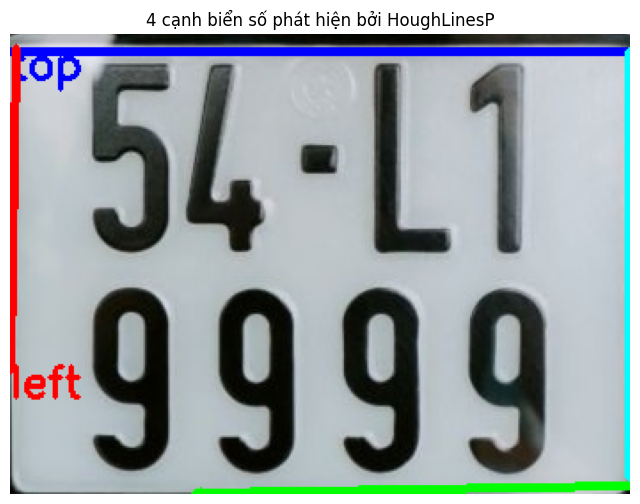

In [18]:
roi_lines_vis = roi.copy()

for line, color, label in [
    (top_line, (255, 0, 0), "top"),
    (bottom_line, (0, 255, 0), "bottom"),
    (left_line, (0, 0, 255), "left"),
    (right_line, (255, 255, 0), "right")
]:
    x1, y1, x2, y2 = line
    cv2.line(roi_lines_vis, (x1, y1), (x2, y2), color, 4)
    cv2.putText(roi_lines_vis, label, (x1, y1 + 15),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

show_bgr(roi_lines_vis, "4 cạnh biển số phát hiện bởi HoughLinesP", figsize=(8,6))

In [19]:
def line_to_abc(line):
    x1, y1, x2, y2 = map(float, line)
    A = y2 - y1
    B = x1 - x2
    C = A * x1 + B * y1
    return A, B, C

def intersect(line1, line2):
    A1, B1, C1 = line_to_abc(line1)
    A2, B2, C2 = line_to_abc(line2)
    det = A1 * B2 - A2 * B1
    if abs(det) < 1e-8:
        return None
    x = (C1 * B2 - C2 * B1) / det
    y = (A1 * C2 - A2 * C1) / det
    return np.array([x, y], dtype=np.float32)

def order_points(pts):
    pts = np.array(pts, dtype=np.float32)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).reshape(-1)
    ordered = np.zeros((4, 2), dtype=np.float32)
    ordered[0] = pts[np.argmin(s)]
    ordered[1] = pts[np.argmin(d)]
    ordered[2] = pts[np.argmax(s)]
    ordered[3] = pts[np.argmax(d)]
    return ordered

tl = intersect(top_line, left_line)
tr = intersect(top_line, right_line)
br = intersect(bottom_line, right_line)
bl = intersect(bottom_line, left_line)

if any(p is None for p in [tl, tr, br, bl]):
    raise ValueError("Có line song song hoặc không tính được giao điểm.")

quad_roi = order_points([tl, tr, br, bl])
print("4 giao điểm trong ROI:")
print(quad_roi)

4 giao điểm trong ROI:
[[  2.9668508  10.       ]
 [348.         10.       ]
 [348.        254.       ]
 [ -1.1722232 259.72412  ]]


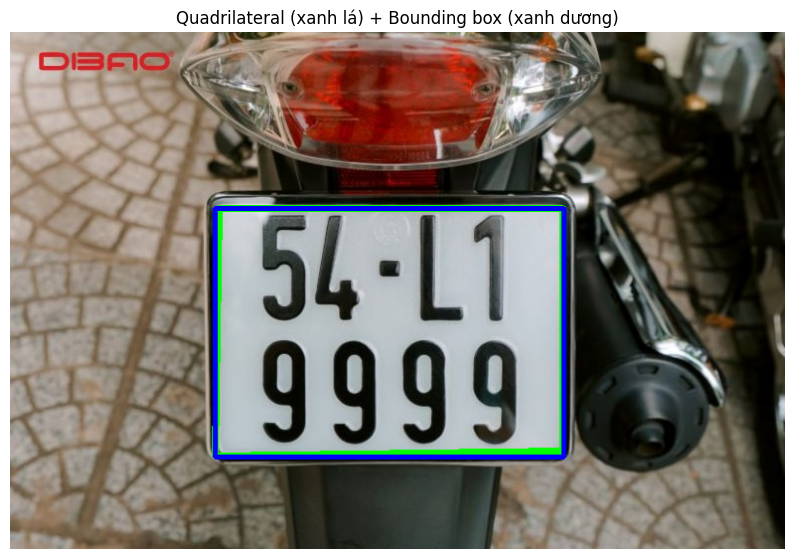

Bounding box cuối cùng: x=206, y=177, w=351, h=250


In [20]:
quad_full = quad_roi + np.array([x0, y0], dtype=np.float32)
quad_int = quad_full.astype(np.int32)

vis = img.copy()
cv2.polylines(vis, [quad_int.reshape(-1,1,2)], True, (0, 255, 0), 6)

bx, by, bw, bh = cv2.boundingRect(quad_int.reshape(-1,1,2))
cv2.rectangle(vis, (bx, by), (bx + bw, by + bh), (255, 0, 0), 4)

show_bgr(vis, "Quadrilateral (xanh lá) + Bounding box (xanh dương)", figsize=(10,7))
print(f"Bounding box cuối cùng: x={bx}, y={by}, w={bw}, h={bh}")

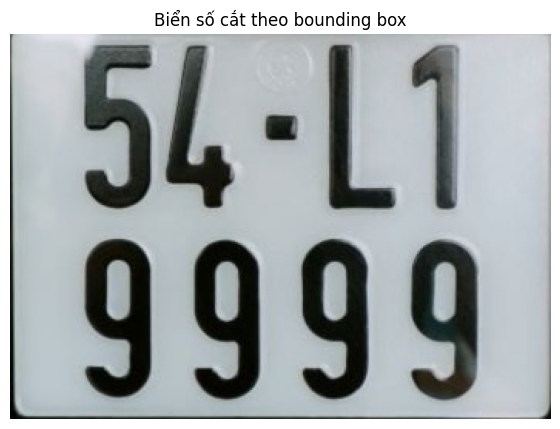

Đã lưu: plate_crop_bbox.png


In [34]:
crop_bbox = img[by:by+bh, bx:bx+bw]
show_bgr(crop_bbox, "Biển số cắt theo bounding box", figsize=(8,5))
outputs = '../outputs/plate_crop_bbox.png'

cv2.imwrite(outputs, crop_bbox)
print("Đã lưu: plate_crop_bbox.png")

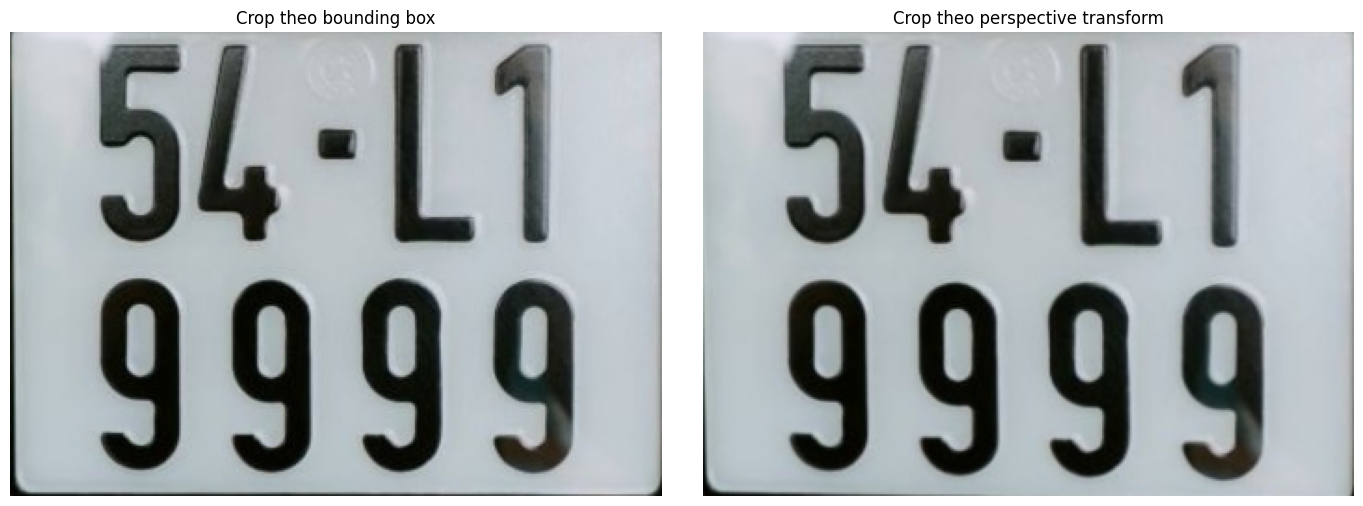

Đã lưu: plate_warp.png


In [29]:
def four_point_transform(image, pts):
    rect = order_points(pts)
    (tl, tr, br, bl) = rect

    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxW = int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxH = int(max(heightA, heightB))

    dst = np.array([
        [0, 0],
        [maxW - 1, 0],
        [maxW - 1, maxH - 1],
        [0, maxH - 1]
    ], dtype=np.float32)

    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxW, maxH))
    return warped

plate_warp = four_point_transform(img, quad_full)

outputs = '../outputs/plate_warp.png'

show_many(
    [crop_bbox, plate_warp],
    ["Crop theo bounding box", "Crop theo perspective transform"],
    figsize=(14,5),
    ncols=2
)

cv2.imwrite(outputs, plate_warp)
print("Đã lưu: plate_warp.png")